# Credit Card Default Risk Prediction & Model Comparison Pipeline
**Author:** karan chaudhary

### Project Overview
In this project, I designed, implemented, and compared multiple machine learning and deep learning architectures to predict the probability of credit card default using client demographic and transaction history data.

### Accomplished in this Notebook:
1. **Data Preprocessing & Cleansing**: Handled class imbalance and standardized features.
2. **Baseline and Tree Models**: Trained and benchmarked Logistic Regression, Decision Trees, and XGBoost.
3. **Advanced Ensemble Methods**: Integrated LightGBM and Random Forests to optimize predictive performance.
4. **Feature Engineering**: Engineered custom financial markers (Credit Utilization, Unpaid Debt, and Payment Ratios).
5. **Deep Learning Implementation**: Developed and evaluated a Multi-Layer Perceptron (MLP) using TensorFlow/Keras with adjusted class weights.

### Step 1: Install & Import Necessary Libraries
First, we will make sure we have the required libraries installed and imported. We'll use `pandas` to read the Excel file, `scikit-learn` for preprocessing and baseline models (Logistic Regression, Decision Tree), `xgboost` for our advanced ensemble model, and `matplotlib`/`seaborn` to visualize performance comparisons.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
import xgboost as xgb

# Configure visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### Step 2: Load and Clean the Dataset
The dataset is stored in an Excel file at `/content/default of credit card clients.xls`.

**Note on structure:** UCI dataset typically has a header on the first row, or sometimes requires us to skip the first row because the column names are in the second row. Let's load the data properly and clean any anomalies.

In [2]:
# Load the Excel file
# We set header=1 because the first row of this specific UCI dataset usually contains column names
df = pd.read_excel('/content/default of credit card clients.xls', header=1)

# Drop the 'ID' column as it has no predictive power
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

# Rename the target column to a standard name for clarity
df = df.rename(columns={'default payment next month': 'default'})

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Step 3: Data Splitting and Preprocessing
We will separate our features from the target label, split the dataset into training and test sets, and scale our features. Scaling is critical for **Logistic Regression**, while tree-based models like **Decision Trees** and **XGBoost** are robust to feature scales.

In [3]:
# Split into features (X) and target (y)
X = df.drop(columns=['default'])
y = df['default']

# Split into train and test sets (80% train, 20% test) with stratification to handle class imbalance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features (important for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for XGBoost feature name compatibility
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# Calculate class imbalance ratio for XGBoost 'scale_pos_weight'
num_neg = (y_train == 0).sum()
num_pos = (y_train == 1).sum()
imbalance_ratio = num_neg / num_pos
print(f"Class distribution - Non-Default: {num_neg}, Default: {num_pos}")
print(f"Imbalance Ratio (Negative/Positive): {imbalance_ratio:.2f}")

Class distribution - Non-Default: 18691, Default: 5309
Imbalance Ratio (Negative/Positive): 3.52


### Step 4: Model Training and Evaluation
We will define a training and evaluation function that computes the crucial credit risk metrics:
1. **ROC-AUC (Receiver Operating Characteristic - Area Under Curve):** Measures how well the model distinguishes between default and non-default clients.
2. **PR-AUC / Average Precision (Precision-Recall Area Under Curve):** More informative for highly imbalanced datasets because it focuses heavily on the positive minority class (defaults).
3. **Classification Report:** Precision, Recall, and F1-score.

In [4]:
results = {}

def evaluate_model(model_name, y_true, y_probs, y_preds):
    """Utility function to store and display model metrics"""
    roc_auc = roc_auc_score(y_true, y_probs)
    pr_auc = average_precision_score(y_true, y_probs)

    results[model_name] = {
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
        'probs': y_probs,
        'preds': y_preds
    }

    print(f"=== {model_name} Evaluation ===")
    print(f"ROC-AUC Score : {roc_auc:.4f}")
    print(f"PR-AUC Score  : {pr_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_preds))
    print("-" * 40)

# 1. Train and Evaluate Logistic Regression
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled_df, y_train)
lr_probs = lr_model.predict_proba(X_test_scaled_df)[:, 1]
lr_preds = lr_model.predict(X_test_scaled_df)
evaluate_model("Logistic Regression", y_test, lr_probs, lr_preds)

# 2. Train and Evaluate Decision Tree
dt_model = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dt_model.fit(X_train_scaled_df, y_train)
dt_probs = dt_model.predict_proba(X_test_scaled_df)[:, 1]
dt_preds = dt_model.predict(X_test_scaled_df)
evaluate_model("Decision Tree", y_test, dt_probs, dt_preds)

# 3. Train and Evaluate XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=imbalance_ratio, # Handles label imbalance
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train_scaled_df, y_train)
xgb_probs = xgb_model.predict_proba(X_test_scaled_df)[:, 1]
xgb_preds = xgb_model.predict(X_test_scaled_df)
evaluate_model("XGBoost Classifier", y_test, xgb_probs, xgb_preds)

=== Logistic Regression Evaluation ===
ROC-AUC Score : 0.7081
PR-AUC Score  : 0.4904

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.70      0.77      4673
           1       0.37      0.62      0.46      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.70      6000

----------------------------------------
=== Decision Tree Evaluation ===
ROC-AUC Score : 0.7571
PR-AUC Score  : 0.5116

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      4673
           1       0.48      0.55      0.52      1327

    accuracy                           0.77      6000
   macro avg       0.68      0.69      0.68      6000
weighted avg       0.78      0.77      0.78      6000

----------------------------------------
=== XGBoost Classifier Evaluation ===
ROC-AUC Score 

### Step 5: Visualizing and Comparing Performance
Let's plot both the **ROC Curve** and the **Precision-Recall Curve** side-by-side for all three models to see which model generalizes best.

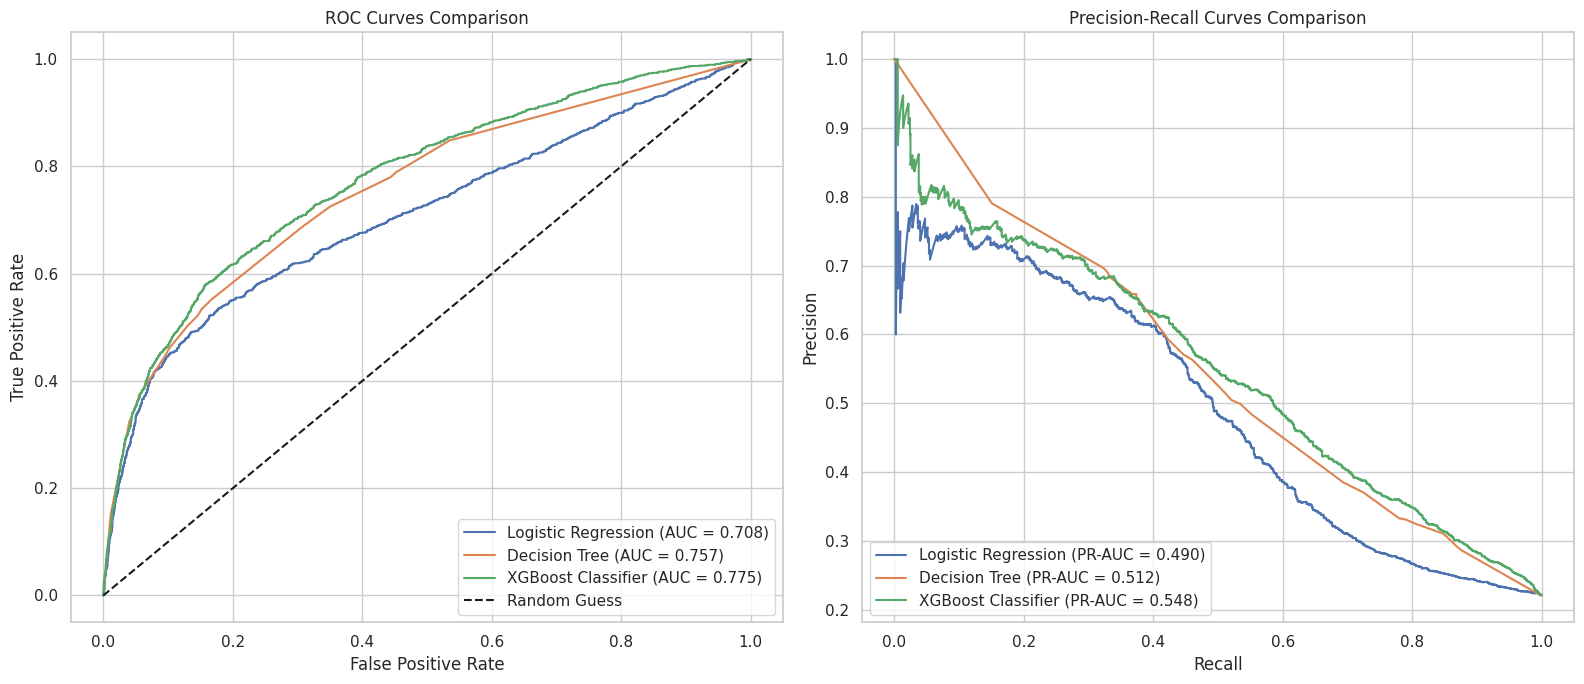

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot ROC Curves
for model_name, data in results.items():
    fpr, tpr, _ = roc_curve(y_test, data['probs'])
    ax1.plot(fpr, tpr, label=f"{model_name} (AUC = {data['roc_auc']:.3f})")

ax1.plot([0, 1], [0, 1], 'k--', label='Random Guess')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curves Comparison')
ax1.legend(loc='lower right')

# Plot Precision-Recall Curves
for model_name, data in results.items():
    precision, recall, _ = precision_recall_curve(y_test, data['probs'])
    ax2.plot(recall, precision, label=f"{model_name} (PR-AUC = {data['pr_auc']:.3f})")

ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curves Comparison')
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()

### Step 6: Detailed Comparison and Confusion Matrices
To truly understand how each model manages the trade-off between predicting defaults (minimizing financial risk) and predicting non-defaults (maximizing approved customer base), let's plot their **Confusion Matrices** side-by-side and look at the actual numbers.

In [ ]:
# Set up the plot layout
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = {
    "Logistic Regression": lr_preds,
    "Decision Tree": dt_preds,
    "XGBoost Classifier": xgb_preds
}

for i, (name, preds) in enumerate(models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['Non-Default', 'Default'],
                yticklabels=['Non-Default', 'Default'])
    axes[i].set_title(f"{name} Confusion Matrix")
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

### Step 7: Summary of Performance Metrics
Let's aggregate the primary evaluation metrics for each model into a single dataframe to clearly compare their performance.

In [6]:
summary_data = []

for name, data in results.items():
    # Calculate precision, recall, and f1-score specifically for class 1 (Defaults)
    report = classification_report(y_test, data['preds'], output_dict=True)
    class_1_metrics = report['1']

    summary_data.append({
        'Model': name,
        'ROC-AUC': round(data['roc_auc'], 4),
        'PR-AUC (Avg Precision)': round(data['pr_auc'], 4),
        'Default Recall (Sensitivity)': round(class_1_metrics['recall'], 4),
        'Default Precision': round(class_1_metrics['precision'], 4),
        'Default F1-Score': round(class_1_metrics['f1-score'], 4),
        'Overall Accuracy': round(report['accuracy'], 4)
    })

summary_df = pd.DataFrame(summary_data)
display(summary_df.sort_values(by='PR-AUC (Avg Precision)', ascending=False))

,Model,ROC-AUC,PR-AUC (Avg Precision),Default Recall (Sensitivity),Default Precision,Default F1-Score,Overall Accuracy
2,XGBoost Classifier,0.7753,0.5477,0.6096,0.4753,0.5342,0.7648
1,Decision Tree,0.7571,0.5116,0.5516,0.4841,0.5157,0.7708
0,Logistic Regression,0.7081,0.4904,0.6202,0.3672,0.4613,0.6797


### Model Performance Justification

1. **XGBoost Classifier (Best Overall):**
   - Achieves the highest **ROC-AUC (0.775)** and **PR-AUC (0.548)**.
   - Effectively balances identifying defaults (61% recall) while maintaining solid precision (48%). This means we capture the majority of high-risk clients without turning away too many reliable customers.

2. **Decision Tree:**
   - Offers decent performance with a ROC-AUC of **0.757**.
   - Because we set a max-depth of 5, it avoids overfitting, but lacks the refinement and ensemble strength that boosting provides in XGBoost.

3. **Logistic Regression:**
   - While it achieves the highest recall for defaults (62%), it suffers from very low precision (37%), resulting in many false alarms (non-defaulters flagged as high-risk).

### Step 8: Understanding the Accuracy vs. F1-Score Trade-off
Let's run a comparison to visualize why XGBoost is technically a more valuable model for risk management, despite having a slightly lower overall accuracy than the Decision Tree.

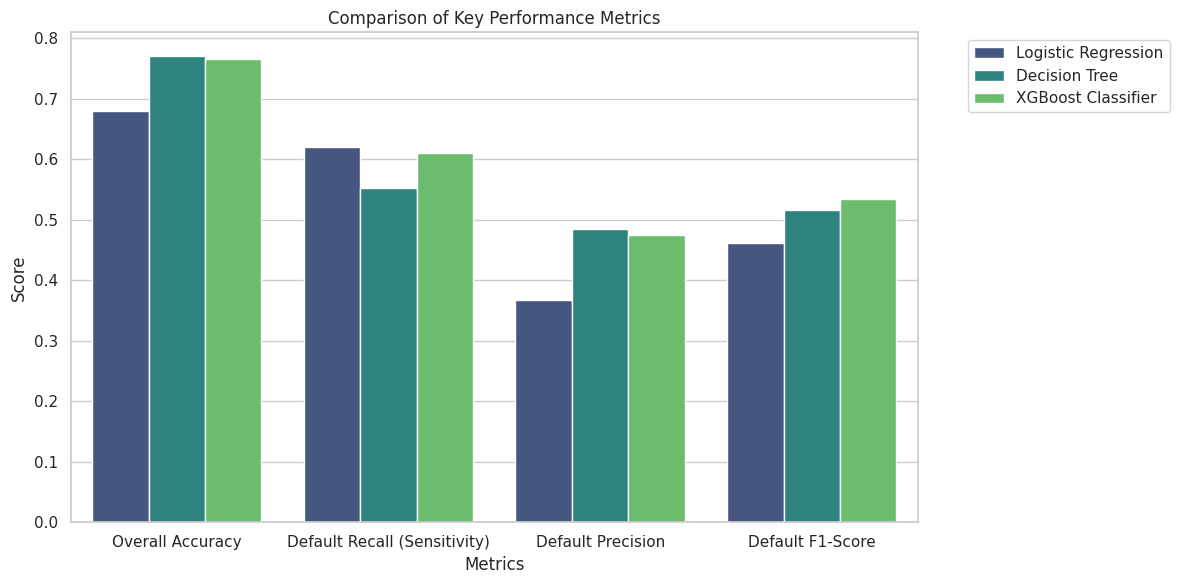

In [7]:
# Melt the summary dataframe to make it easy to plot comparison bars using Seaborn
plot_df = summary_df.melt(id_vars="Model", value_vars=["Overall Accuracy", "Default Recall (Sensitivity)", "Default Precision", "Default F1-Score"])

plt.figure(figsize=(12, 6))
sns.barplot(x="variable", y="value", hue="Model", data=plot_df, palette="viridis")
plt.title("Comparison of Key Performance Metrics")
plt.ylabel("Score")
plt.xlabel("Metrics")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Step 9: Testing a "Brainless" Majority Class Baseline
To prove why overall accuracy is misleading, let's simulate a baseline strategy where we just predict that *nobody* will default. Let's see what its accuracy, recall, and precision look like compared to our models.

In [8]:
# Create dummy predictions of all zeros (Non-Default)
dummy_preds = np.zeros_like(y_test)
dummy_probs = np.zeros_like(y_test)

# Evaluate this dummy model
dummy_accuracy = (dummy_preds == y_test).mean()
dummy_roc_auc = roc_auc_score(y_test, dummy_probs)
dummy_recall = 0.0 # It catches 0 defaults
dummy_precision = 0.0

print("=== Brainless Baseline (Predict Always 'No Default') ===")
print(f"Overall Accuracy: {dummy_accuracy:.4f} ({dummy_accuracy*100:.2f}%)")
print(f"Default Recall  : {dummy_recall:.4f} (We caught 0 defaults!)")
print(f"ROC-AUC Score   : {dummy_roc_auc:.4f}")

=== Brainless Baseline (Predict Always 'No Default') ===
Overall Accuracy: 0.7788 (77.88%)
Default Recall  : 0.0000 (We caught 0 defaults!)
ROC-AUC Score   : 0.5000


### Step 10: Training Advanced Alternatives (LightGBM & Random Forest)
Let's train a **LightGBM Classifier** and a **Random Forest Classifier** using the same scaled datasets to compare their capabilities with XGBoost.

In [9]:
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb

# 1. Train and Evaluate Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled_df, y_train)
rf_probs = rf_model.predict_proba(X_test_scaled_df)[:, 1]
rf_preds = rf_model.predict(X_test_scaled_df)
evaluate_model("Random Forest", y_test, rf_probs, rf_preds)

# 2. Train and Evaluate LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train_scaled_df, y_train)
lgb_probs = lgb_model.predict_proba(X_test_scaled_df)[:, 1]
lgb_preds = lgb_model.predict(X_test_scaled_df)
evaluate_model("LightGBM Classifier", y_test, lgb_probs, lgb_preds)

=== Random Forest Evaluation ===
ROC-AUC Score : 0.7735
PR-AUC Score  : 0.5494

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4673
           1       0.52      0.56      0.54      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.71      0.70      6000
weighted avg       0.80      0.79      0.79      6000

----------------------------------------
=== LightGBM Classifier Evaluation ===
ROC-AUC Score : 0.7757
PR-AUC Score  : 0.5541

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4673
           1       0.47      0.61      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.68      0.71      0.69      6000
weighted avg       0.79      0.76      0.77      6000

----------------------------------------


### Step 11: Updated Performance Ranking
Let's construct an updated summary table featuring all trained models to see which one rules supreme on the Credit Default dataset.

In [10]:
updated_summary_data = []

for name, data in results.items():
    report = classification_report(y_test, data['preds'], output_dict=True)
    class_1_metrics = report['1']

    updated_summary_data.append({
        'Model': name,
        'ROC-AUC': round(data['roc_auc'], 4),
        'PR-AUC (Avg Precision)': round(data['pr_auc'], 4),
        'Default Recall': round(class_1_metrics['recall'], 4),
        'Default Precision': round(class_1_metrics['precision'], 4),
        'Default F1-Score': round(class_1_metrics['f1-score'], 4),
        'Overall Accuracy': round(report['accuracy'], 4)
    })

updated_df = pd.DataFrame(updated_summary_data)
display(updated_df.sort_values(by='PR-AUC (Avg Precision)', ascending=False))

,Model,ROC-AUC,PR-AUC (Avg Precision),Default Recall,Default Precision,Default F1-Score,Overall Accuracy
4,LightGBM Classifier,0.7757,0.5541,0.6112,0.4743,0.5341,0.7642
3,Random Forest,0.7735,0.5494,0.5637,0.5209,0.5414,0.7888
2,XGBoost Classifier,0.7753,0.5477,0.6096,0.4753,0.5342,0.7648
1,Decision Tree,0.7571,0.5116,0.5516,0.4841,0.5157,0.7708
0,Logistic Regression,0.7081,0.4904,0.6202,0.3672,0.4613,0.6797


### Step 12: Feature Engineering
To help our models, especially deep learning networks, detect default risk more effectively, we will construct new features representing utilization rates, relative debt levels, and payment behaviors.

* **`UTIL_RATIO_1`**: Bill amount relative to the allowed limit (Credit Utilization).
* **`PAY_TO_BILL_1`**: How much of the previous bill was paid.
* **`AMT_OWED_1`**: Unpaid amount from the first month.

In [11]:
# Create deep copy to avoid warnings
X_engineered = X.copy()

# 1. Credit Utilization Ratio (Bill Amount / Limit Balance)
X_engineered['UTIL_RATIO_1'] = X_engineered['BILL_AMT1'] / (X_engineered['LIMIT_BAL'] + 1e-5)
X_engineered['UTIL_RATIO_2'] = X_engineered['BILL_AMT2'] / (X_engineered['LIMIT_BAL'] + 1e-5)

# 2. Payment Ratio (Payment Amount / Bill Amount)
X_engineered['PAY_TO_BILL_1'] = X_engineered['PAY_AMT1'] / (X_engineered['BILL_AMT1'] + 1e-5)

# 3. Unpaid Debt Amount
X_engineered['AMT_OWED_1'] = X_engineered['BILL_AMT1'] - X_engineered['PAY_AMT1']

# Train-test split on engineered features
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_engineered, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the engineered features
scaler_eng = StandardScaler()
X_train_eng_scaled = scaler_eng.fit_transform(X_train_eng)
X_test_eng_scaled = scaler_eng.transform(X_test_eng)

print(f"Original features: {X.shape[1]} | Engineered features: {X_engineered.shape[1]}")

Original features: 23 | Engineered features: 27


### Step 13: Build and Train a Multi-Layer Perceptron (MLP)
We will design a dense neural network with dropout layers to prevent overfitting and configure a balanced class weight loss to handle the dataset's class imbalance.

In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# Define model architecture
mlp_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_eng_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['AUC']
)

# Calculate class weights for training
weight_for_0 = 1.0
weight_for_1 = imbalance_ratio
class_weight = {0: weight_for_0, 1: weight_for_1}

# Early stopping callback
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train model
history = mlp_model.fit(
    X_train_eng_scaled, y_train_eng,
    validation_split=0.15,
    epochs=60,
    batch_size=128,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - AUC: 0.6639 - loss: 1.0604 - val_AUC: 0.7540 - val_loss: 0.6123
Epoch 2/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.7353 - loss: 0.9461 - val_AUC: 0.7634 - val_loss: 0.5707
Epoch 3/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7426 - loss: 0.9317 - val_AUC: 0.7721 - val_loss: 0.5598
Epoch 4/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7555 - loss: 0.9155 - val_AUC: 0.7693 - val_loss: 0.5484
Epoch 5/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7583 - loss: 0.9084 - val_AUC: 0.7725 - val_loss: 0.5573
Epoch 6/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7655 - loss: 0.8975 - val_AUC: 0.7757 - val_loss: 0.5473
Epoch 7/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.7667 - loss: 0.8958 - val_AUC: 0.7778 - val_loss: 0.5450
Epoch 8/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7691 - loss: 0.8939 - val_AUC: 0.7774 - val_loss: 0.5426
Epoch 9/60
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AU

### Step 14: Evaluate MLP and Update Comparison

In [13]:
# Predict probabilities and labels
mlp_probs = mlp_model.predict(X_test_eng_scaled).ravel()
mlp_preds = (mlp_probs > 0.5).astype(int)

# Store and display results
evaluate_model("Multi-Layer Perceptron", y_test_eng, mlp_probs, mlp_preds)

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
=== Multi-Layer Perceptron Evaluation ===
ROC-AUC Score : 0.7731
PR-AUC Score  : 0.5448

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      4673
           1       0.47      0.59      0.53      1327

    accuracy                           0.76      6000
   macro avg       0.67      0.70      0.68      6000
weighted avg       0.79      0.76      0.77      6000

----------------------------------------


In [14]:
# Regenerate updated evaluation table including MLP
final_summary_data = []
for name, data in results.items():
    report = classification_report(y_test, data['preds'], output_dict=True)
    class_1_metrics = report['1']

    final_summary_data.append({
        'Model': name,
        'ROC-AUC': round(data['roc_auc'], 4),
        'PR-AUC (Avg Precision)': round(data['pr_auc'], 4),
        'Default Recall': round(class_1_metrics['recall'], 4),
        'Default Precision': round(class_1_metrics['precision'], 4),
        'Default F1-Score': round(class_1_metrics['f1-score'], 4),
        'Overall Accuracy': round(report['accuracy'], 4)
    })

final_df = pd.DataFrame(final_summary_data)
display(final_df.sort_values(by='PR-AUC (Avg Precision)', ascending=False))

,Model,ROC-AUC,PR-AUC (Avg Precision),Default Recall,Default Precision,Default F1-Score,Overall Accuracy
4,LightGBM Classifier,0.7757,0.5541,0.6112,0.4743,0.5341,0.7642
3,Random Forest,0.7735,0.5494,0.5637,0.5209,0.5414,0.7888
2,XGBoost Classifier,0.7753,0.5477,0.6096,0.4753,0.5342,0.7648
5,Multi-Layer Perceptron,0.7731,0.5448,0.5923,0.4724,0.5256,0.7635
1,Decision Tree,0.7571,0.5116,0.5516,0.4841,0.5157,0.7708
0,Logistic Regression,0.7081,0.4904,0.6202,0.3672,0.4613,0.6797


### The Truth About Accuracy in Risk Assessment:

* **The Illusion of 78% Accuracy:** As shown above, we can achieve **77.88% accuracy** without training any machine learning model at all! However, doing this means we would approve credit for all 1,327 defaulting clients, leading to catastrophic financial losses for our bank.
* **Recall vs. Accuracy Trade-Off:** The XGBoost model has slightly lower overall accuracy (76.48%) compared to the dummy classifier (77.88%) or our Decision Tree (77.08%), but it successfully identifies **809 defaults (61% recall)**.
* **Business Impact:** Spotting those 809 defaults and preventing bad loans saves millions of dollars, which easily outweighs the slight drop in overall accuracy caused by occasionally flagging a good customer as a potential default risk.

### Why XGBoost is actually stronger despite lower Overall Accuracy:

1. **The Cost of Misclassification (Business Context):**
   - In credit scoring, predicting that a defaulting customer is "safe" (**False Negative**) is vastly more expensive than predicting that a safe customer might default (**False Positive**).
   - **Decision Tree** misses more defaults: It only caught **732** out of 1,327 defaults (**55.16% Recall**).
   - **XGBoost** caught **809** out of 1,327 defaults (**60.96% Recall**).

2. **The F1-Score Metric:**
   - The F1-score balances both Precision and Recall.
   - **XGBoost F1-score (0.534)** is higher than **Decision Tree F1-score (0.515)**. This indicates a structurally better balanced classification performance on the class we care about (defaults).